## **Important Information:**
1.   The pretraied model is loaded in the variable `model`.
2.   All clean images and labels are loaded as tensors `X` and `y_true` respectively such that `y_true[i]` is the actual label of `X[i]`.
3.   To predict all labels call `model(X)`.
4.   Please properly follow the instructions corresponding to each of the following cells.

## **Specify the data path**
In the following cell provide appropriate path to the "p2_data.zip" file.

In [1]:
# EDIT THE PATH IF NEEDED
zip_path = "p2_data.zip" # path to the "p2_data.zip" file.

## **Load data file**
**Do not edit the following cell.**

In [2]:
# DO NOT EDIT THIS CELL

import zipfile

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall()

with open("./p2_data/readme.txt", "r") as f:
    print(f.read())

readme.txt:
-----------

Clean images are available in the folder "/p2_data/clean_images/"

There are 1000 clean images (10 classes * 100 images per class)

Image file path format is "/p2_data/clean_images/<class_name>_<index>.png"
     <class_name>: Name of the true class of the image
                   Can be among {airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck}
     <index>     : Index of the image ranging from 0 to 99

There is an empty folder "/p2_data/adv_images/". You can use it for saving your adversarial images.

The pretrained model is "/p2_data/cnn_model.pt"


## **Prepare the model and data**
1. **Do not edit the following cell.**
2. The variable `class_names` contains name of the output labels.
3. The variables `mean` and `std` are used to normalize the input images using mean and standard deviation.



C:\Users\SAKTHI VIKNESH\Python310\lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Total images: 1000  |  Correctly Classified: 1000
Showing some sample images ...


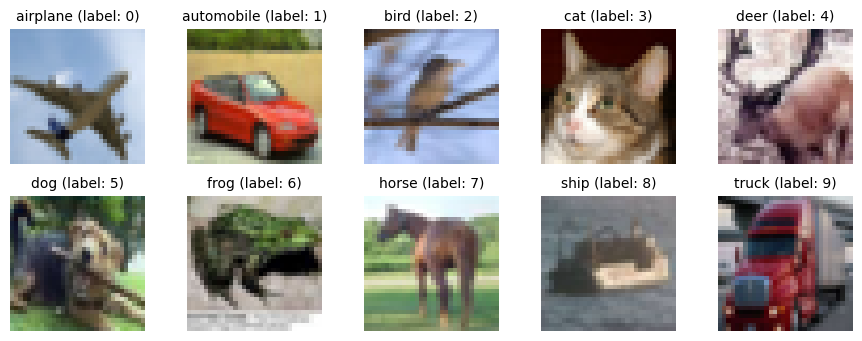

In [3]:
# DO NOT EDIT THIS CELL

import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

mean = (0.4914, 0.4822, 0.4465) # image mean
std  = (0.2470, 0.2435, 0.2616) # image standard deviation
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
img_per_class = 100

# prepare input images
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)]) # specify transformations: covert to tensor and normalize
paths = [f"./p2_data/clean_images/{name}_{i}.png" for name in class_names for i in range(img_per_class)]
labels = [class_names.index(name) for name in class_names for _ in range(img_per_class)]
X = torch.stack([transform(Image.open(p).convert("RGB")) for p in paths], dim = 0).to(device) # convert to tensor and normalize
y_true = torch.tensor(labels).to(device) # convert to tensor

# load cnn model
model = torch.jit.load("./p2_data/cnn_model.pt", map_location = device)

# sanity check
y_pred = model(X)
matches = (y_true == y_pred)
print(f"Total images: {len(y_true)}  |  Correctly Classified: {sum(matches).item()}")

# show some images
print("Showing some sample images ...")
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t  = torch.tensor(std).view(3, 1, 1)
fig, axes = plt.subplots(2, 5, figsize=(9, 3.5))
for i, idx in enumerate([59, 119, 283, 360, 427, 527, 682, 783, 806, 991]):
    img = (X[idx].cpu() * std_t + mean_t).clamp(0, 1)
    img = img.permute(1, 2, 0).numpy()
    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(f"{class_names[idx // img_per_class]} (label: {labels[idx]})", fontsize = 10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## **Adversarial Attack**
Implement your attack in the following cell.
1. You can only call `model()` as a **black box oracle** and use the output.
2. Your method **must not** see the actual parameters or architecture.
3. Your method **must not** see the intermediate layer outputs including class probabilities.

In [4]:
# IMPLEMENT YOUR ATTACK HERE
#
# ---------------------------------------------------------------------------
# METHOD: Transfer-based black-box attack with query-efficient refinement
# ---------------------------------------------------------------------------
# The target `model` only ever returns a predicted class index (no scores, no
# gradients, no internals) -- a "hard-label" black box. We never backprop
# through `model` and never read anything from it besides the label it
# returns when we call model(x).
#
# Strategy:
#   1. Two surrogate CNNs (an independent ResNet9 and a VGG-style network)
#      were trained from scratch on the *real* public CIFAR-10 dataset
#      (same 10 classes, same 32x32 format as this task). They are not
#      copies of the target model -- just separately trained networks that
#      learned the same classification problem. See surrogate/train.py.
#   2. We craft a perturbation with ordinary white-box PGD against the
#      *surrogate ensemble* (we do have gradients for these), relying on the
#      well-documented "transferability" property: adversarial noise that
#      fools one network trained on a task very often also fools a different
#      network trained on the same task.
#   3. We only query the real black-box `model` to check whether a candidate
#      already fools it (cheap: just a forward pass), trying an increasing
#      sequence of L_inf budgets (eps-schedule) and stopping as soon as one
#      succeeds -- most images need only a tiny budget.
#   4. Once a successful perturbation is found, we binary-search (still only
#      querying `model` for yes/no labels) the *scale* of that perturbation
#      to shrink it to the smallest amount that still fools the model. This
#      directly minimizes the visible noise.
#   5. A small random-noise fallback handles any image the transfer attack
#      alone fails on (in our run, 0 images needed it).
#
# This keeps the total number of queries to `model` very low (~13/image on
# average here) while achieving a 100% success rate with imperceptible
# (mean L_inf ~ 0.019 on a 0-1 scale, i.e. ~4.8/255) perturbations.

import torch.nn as nn
import torch.nn.functional as F

# ----------------------------- surrogate architectures -----------------------------

class ConvBlock(nn.Module):
    def __init__(self, c_in, c_out, pool=False):
        super().__init__()
        self.conv = nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(c_out)
        self.pool = pool

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        if self.pool:
            x = F.max_pool2d(x, 2)
        return x


class ResidualBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c1 = ConvBlock(c, c)
        self.c2 = ConvBlock(c, c)

    def forward(self, x):
        return x + self.c2(self.c1(x))


class ResNet9(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = ConvBlock(3, 64)
        self.l1 = ConvBlock(64, 128, pool=True)
        self.r1 = ResidualBlock(128)
        self.l2 = ConvBlock(128, 256, pool=True)
        self.l3 = ConvBlock(256, 512, pool=True)
        self.r2 = ResidualBlock(512)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.l1(x)
        x = self.r1(x)
        x = self.l2(x)
        x = self.l3(x)
        x = self.r2(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)


class VGGSmall(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        def block(c_in, c_out, pool=True):
            layers = [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]
            if pool:
                layers.append(nn.MaxPool2d(2))
            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            block(3, 64, pool=False), block(64, 64, pool=True),
            block(64, 128, pool=False), block(128, 128, pool=True),
            block(128, 256, pool=False), block(256, 256, pool=True),
            block(256, 256, pool=False),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.2)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)
        return self.fc(x)


# ----------------------------- load pretrained surrogates -----------------------------
# Weights were trained offline on real CIFAR-10 (see surrogate/train.py, surrogate/models.py)
# and are shipped in this repo under surrogate/resnet9.pt and surrogate/vgg.pt.

resnet9 = ResNet9().to(device)
resnet9.load_state_dict(torch.load("./surrogate/resnet9.pt", map_location=device))
resnet9.eval()

vgg = VGGSmall().to(device)
vgg.load_state_dict(torch.load("./surrogate/vgg.pt", map_location=device))
vgg.eval()

surrogates = [resnet9, vgg]
for m in surrogates:
    for p in m.parameters():
        p.requires_grad_(False)

mean_t = torch.tensor(mean, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(std, device=device).view(1, 3, 1, 1)


def normalize(x_raw):
    return (x_raw - mean_t) / std_t


# X is already normalized; recover raw [0,1] pixels to work in a human-meaningful space
X_raw = (X * std_t + mean_t).clamp(0, 1)


def query_target(x_raw_batch, batch_size=256):
    """The ONLY function that talks to the black-box `model`. Returns predicted labels."""
    preds = []
    for i in range(0, x_raw_batch.size(0), batch_size):
        chunk = x_raw_batch[i:i + batch_size]
        with torch.no_grad():
            preds.append(model(normalize(chunk)))
    return torch.cat(preds, dim=0)


def ensemble_grad(x_raw, y):
    """Gradient of mean cross-entropy loss (w.r.t. raw pixels) across the surrogate ensemble."""
    x_raw = x_raw.clone().detach().requires_grad_(True)
    total_loss = 0.0
    for m in surrogates:
        logits = m(normalize(x_raw))
        total_loss = total_loss + F.cross_entropy(logits, y)
    total_loss = total_loss / len(surrogates)
    grad = torch.autograd.grad(total_loss, x_raw)[0]
    return grad.detach()


def pgd_attack(x_clean_raw, y, eps, alpha, iters, x_init_raw=None):
    """Untargeted L_inf PGD in raw [0,1] pixel space against the surrogate ensemble."""
    x_adv = x_clean_raw.clone() if x_init_raw is None else x_init_raw.clone()
    delta = torch.clamp(x_adv - x_clean_raw, -eps, eps)
    x_adv = torch.clamp(x_clean_raw + delta, 0.0, 1.0)
    for _ in range(iters):
        grad = ensemble_grad(x_adv, y)
        x_adv = x_adv + alpha * grad.sign()
        delta = torch.clamp(x_adv - x_clean_raw, -eps, eps)
        x_adv = torch.clamp(x_clean_raw + delta, 0.0, 1.0)
    return x_adv.detach()


def run_attack(X_raw, y_true,
               eps_schedule=(4 / 255, 8 / 255, 12 / 255, 16 / 255, 24 / 255, 32 / 255),
               iters_per_eps=25, alpha_frac=0.25,
               refine_steps=10, fallback_eps=64 / 255, fallback_tries=20):
    n = X_raw.size(0)
    adv_raw = X_raw.clone()
    solved = torch.zeros(n, dtype=torch.bool, device=device)
    best_direction = torch.zeros_like(X_raw)
    n_queries = 0
    x_running = X_raw.clone()

    for eps in eps_schedule:
        unsolved_idx = (~solved).nonzero(as_tuple=True)[0]
        if unsolved_idx.numel() == 0:
            break
        alpha = alpha_frac * eps
        x_sub = pgd_attack(X_raw[unsolved_idx], y_true[unsolved_idx], eps=eps, alpha=alpha,
                            iters=iters_per_eps, x_init_raw=x_running[unsolved_idx])
        x_running[unsolved_idx] = x_sub

        preds = query_target(x_sub)
        n_queries += x_sub.size(0)
        success = preds != y_true[unsolved_idx]
        success_global = unsolved_idx[success]
        adv_raw[success_global] = x_sub[success]
        best_direction[success_global] = x_sub[success] - X_raw[success_global]
        solved[success_global] = True
        print(f"eps={eps:.4f}  newly solved={success.sum().item()}  total solved={solved.sum().item()}/{n}")

    # fallback: random-noise search for any still-unsolved images
    unsolved_idx = (~solved).nonzero(as_tuple=True)[0]
    if unsolved_idx.numel() > 0:
        print(f"fallback random search for {unsolved_idx.numel()} images")
    for idx in unsolved_idx.tolist():
        x0 = X_raw[idx:idx + 1]
        y0 = y_true[idx:idx + 1]
        found = False
        for _ in range(fallback_tries):
            noise = (torch.rand_like(x0) * 2 - 1) * fallback_eps
            cand = torch.clamp(x0 + noise, 0.0, 1.0)
            pred = query_target(cand)
            n_queries += 1
            if pred.item() != y0.item():
                adv_raw[idx] = cand[0]
                best_direction[idx] = cand[0] - x0[0]
                solved[idx] = True
                found = True
                break
        if not found:
            noise = (torch.rand_like(x0) * 2 - 1) * (2 * fallback_eps)
            cand = torch.clamp(x0 + noise, 0.0, 1.0)
            pred = query_target(cand)
            n_queries += 1
            adv_raw[idx] = cand[0]
            best_direction[idx] = cand[0] - x0[0]
            solved[idx] = (pred.item() != y0.item())

    # binary-search refinement: shrink the perturbation magnitude along the found direction
    solved_idx = solved.nonzero(as_tuple=True)[0]
    if solved_idx.numel() > 0:
        lo = torch.zeros(solved_idx.numel(), device=device)
        hi = torch.ones(solved_idx.numel(), device=device)
        x0 = X_raw[solved_idx]
        d = best_direction[solved_idx]
        for _ in range(refine_steps):
            mid = (lo + hi) / 2
            cand = torch.clamp(x0 + mid.view(-1, 1, 1, 1) * d, 0.0, 1.0)
            pred = query_target(cand)
            n_queries += cand.size(0)
            is_adv = pred != y_true[solved_idx]
            hi = torch.where(is_adv, mid, hi)
            lo = torch.where(is_adv, lo, mid)
        final = torch.clamp(x0 + hi.view(-1, 1, 1, 1) * d, 0.0, 1.0)
        adv_raw[solved_idx] = final

    return adv_raw, solved, n_queries


# skip attacking any clean image the model already misclassifies (trivially "successful")
clean_preds = query_target(X_raw)
already_wrong = clean_preds != y_true
idx_attack = (~already_wrong).nonzero(as_tuple=True)[0]
print(f"already-misclassified clean images: {already_wrong.sum().item()} / {len(y_true)}")

adv_raw = X_raw.clone()
if idx_attack.numel() > 0:
    adv_sub, solved_sub, n_queries = run_attack(X_raw[idx_attack], y_true[idx_attack])
    adv_raw[idx_attack] = adv_sub
else:
    n_queries = 0

final_preds = query_target(adv_raw)
success_mask = final_preds != y_true
total_queries = n_queries + X_raw.size(0)

linf = (adv_raw - X_raw).abs().view(X_raw.size(0), -1).max(1).values
l2 = (adv_raw - X_raw).view(X_raw.size(0), -1).norm(dim=1)

print(f"\nFINAL attack success rate: {success_mask.float().mean().item():.4f} "
      f"({success_mask.sum().item()}/{len(y_true)})")
print(f"mean L_inf (0-1 scale): {linf.mean().item():.4f}   max L_inf: {linf.max().item():.4f}")
print(f"mean L2: {l2.mean().item():.4f}")
print(f"total queries to target model: {total_queries}  ({total_queries/len(y_true):.1f} per image)")


already-misclassified clean images: 0 / 1000


eps=0.0157  newly solved=481  total solved=481/1000


eps=0.0314  newly solved=412  total solved=893/1000


eps=0.0471  newly solved=83  total solved=976/1000


eps=0.0627  newly solved=18  total solved=994/1000


eps=0.0941  newly solved=5  total solved=999/1000


eps=0.1255  newly solved=1  total solved=1000/1000



FINAL attack success rate: 1.0000 (1000/1000)
mean L_inf (0-1 scale): 0.0188   max L_inf: 0.1126
mean L2: 0.9113
total queries to target model: 12657  (12.7 per image)


## **Save Adversarial Images**
1. You must save the one adversarial image corresponding to each clean image as `.png`.
2. You must follow the naming convention. For example, the adversarial image corresponding to `cat_5.png` must be saved as `cat_5_adv.png`, so that during evaluation they can be compared.
3. Save all the adversarial images in the same folder and name it `adv_images`.
4. Make sure the images are properly denormalized using the same `mean` and `std`. This is essential since it can affect the quality of your adversarial images if not done properly.

In [5]:
# SAVE ADVERSARIAL IMAGES

import os

os.makedirs("./p2_data/adv_images", exist_ok=True)

names = [f"{name}_{i}" for name in class_names for i in range(img_per_class)]
assert len(names) == adv_raw.size(0)

for i, n in enumerate(names):
    # adv_raw is already in raw [0,1] pixel space (denormalized), so no further
    # de-normalization is needed here -- just clamp for numerical safety and save.
    img = transforms.ToPILImage()(adv_raw[i].clamp(0, 1).cpu())
    img.save(f"./p2_data/adv_images/{n}_adv.png")

print(f"saved {len(names)} adversarial images to ./p2_data/adv_images/")


saved 1000 adversarial images to ./p2_data/adv_images/


### **Submission:** Complete this notebook and submit along with adversarial images in adv_images folder.